## Statistics for sampled fields in different resolutions

This notebook contains the following plots:

1. Location: Distribution of points in latitude and longitude for all resolutions.
2. Distribution of vortcity values for all track resolutions (maximum along a track)
3. Distance distribution for all resolutions
4. Lifetime distribution for all resolutions

All distributions contains median vals and 1 sigma bounds. 


In [84]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import pystormtracker as pst

module_dir = (Path.cwd() / ".." / ".." / "algorithms").resolve()
sys.path.insert(0, str(module_dir))
import helpers
from configs import REGION, DOMAIN, SL_AREA, SAMPLE_CONFIG
from plotting import setup_plotting, geo_map, add_colorbar
from helpers import tracks_to_points, haversine_km
from statistics_on_tracks import summarise_points

colors = setup_plotting()
plt.rcParams["axes.formatter.limits"] = (-4, 5)   # plain numbers on the axes (e.g. 1000 hPa, not 1.0 x 1e3)

In [85]:
TRACK_DIR = Path("/dmidata/users/asgtho/tracks")
SAMPLE_GRID = "sl0p25"

R_EARTH_KM = 6371.0
GALE, STORM = 17.2, 24.5   # m s-1, Beaufort 8 and 10


def res_from_tag(tag):
    # '0p25' -> 0.25, '1p875' -> 1.875
    return float(tag.replace("p", "."))


def res_label(res):
    return f"{res:g}°"


print(TRACK_DIR)
sorted(p.name for p in TRACK_DIR.glob("*_DJF"))

/dmidata/users/asgtho/tracks


['19981999_DJF',
 '19992000_DJF',
 '20002001_DJF',
 '20012002_DJF',
 '20022003_DJF',
 '20032004_DJF',
 '20042005_DJF',
 '20052006_DJF',
 '20062007_DJF',
 '20072008_DJF',
 '20082009_DJF',
 '20092010_DJF',
 '20102011_DJF',
 '20112012_DJF',
 '20122013_DJF',
 '20132014_DJF',
 '20142015_DJF',
 '20152016_DJF',
 '20162017_DJF',
 '20172018_DJF',
 '20182019_DJF',
 '20192020_DJF',
 '20202021_DJF',
 '20212022_DJF',
 '20222023_DJF',
 '20232024_DJF',
 '20242025_DJF',
 '20252026_DJF']

In [86]:
def boot_hist(x, edges, groups=None, n_boot=1000, ci=(2.5, 97.5), seed=0):
    """Density histogram + bootstrap CI. If `groups` (e.g. track ids) is given,
    whole groups are resampled (block bootstrap); otherwise individual values."""
    rng = np.random.default_rng(seed)
    x = np.asarray(x)
    dens, _ = np.histogram(x, bins=edges, density=True)
    if groups is None:
        samples = (x[rng.integers(0, len(x), len(x))] for _ in range(n_boot))
    else:
        groups = np.asarray(groups)
        blocks = [x[groups == g] for g in np.unique(groups)]
        samples = (np.concatenate([blocks[k] for k in rng.integers(0, len(blocks), len(blocks))])
                   for _ in range(n_boot))
    boot = np.array([np.histogram(s, bins=edges, density=True)[0] for s in samples])
    lo, hi = np.percentile(boot, ci, axis=0)
    return dens, lo, hi


def plot_dist(ax, df, var, xlabel, by="res", levels=None, color=None, nbins=30,
              unit="", group_col=None, clip_pct=99, fmt=".0f"):
    levels = levels or sorted(df[by].unique())
    color = color or {l: colors[i % len(colors)] for i, l in enumerate(levels)}
    vals = df[var].dropna()
    edges = np.linspace(np.percentile(vals, 100 - clip_pct), np.percentile(vals, clip_pct), nbins + 1)

    for lev in levels[::-1]:
        d = df[df[by] == lev].dropna(subset=[var])
        x = d[var].to_numpy()
        g = d[group_col].to_numpy() if group_col else None
        dens, lo, hi = boot_hist(x, edges, groups=g)
        c = color[lev]
        ax.fill_between(edges[:-1], lo, hi, step="post", color=c, alpha=0.2, lw=0)
        ax.stairs(dens, edges, color=c, lw=1.8,
                  label=f"{res_label(lev)}  (median {np.median(x):{fmt}}{unit})")
        ax.axvline(np.median(x), color=c, ls="--", lw=1.2)

    ax.set_xlabel(xlabel); ax.set_ylabel("Probability density")
    ax.set_xlim(edges[0], edges[-1]); ax.set_ylim(bottom=0)
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(axis="y", color="0.9", lw=0.8); ax.set_axisbelow(True)
    h, l = ax.get_legend_handles_labels()
    ax.legend(h[::-1], l[::-1], frameon=False, fontsize=9)

In [87]:
def load_all(kind, track_res="0p25", sample_grid="*", track_dir=TRACK_DIR):
    """kind = 'points' or 'summary'. track_res / sample_grid are tags ('0p25', '1p0') or '*' for all."""
    sl = sample_grid if sample_grid == "*" else f"sl{sample_grid}"
    tables = []
    for season_dir in sorted(track_dir.glob("*_DJF")):
        for path in sorted(season_dir.glob(f"*_{track_res}_vo_{kind}_{sl}.csv")):
            if path.name.startswith("._"):
                continue
            parts = path.stem.split("_")              # 19981999 DJF 0p25 vo points sl1p0
            df = pd.read_csv(path, parse_dates=["time"] if kind == "points" else ["start_time", "end_time"])
            df.insert(0, "season", season_dir.name)
            df.insert(1, "res", res_from_tag(parts[2]))
            df.insert(2, "sample_res", res_from_tag(parts[5].removeprefix("sl")))
            tables.append(df)
            print(f"loaded {len(df)} rows from {path.name}")
    out = pd.concat(tables, ignore_index=True) if tables else pd.DataFrame()
    if not out.empty:
        # track_id is only unique within a season -> make a global key for the bootstrap
        out["track_key"] = out["season"] + "_" + out["track_id"].astype(str)
    return out


points = load_all("points", track_res="0p25")    # all sl grids, tracks from 0.25°
summary = load_all("summary", track_res="0p25")

SAMPLE_RES = sorted(points["sample_res"].unique())
SRES_COLOR = {r: colors[i % len(colors)] for i, r in enumerate(SAMPLE_RES)}

loaded 2047 rows from 19981999_DJF_0p25_vo_points_sl0p25.csv
loaded 2047 rows from 19981999_DJF_0p25_vo_points_sl1p25.csv
loaded 2047 rows from 19981999_DJF_0p25_vo_points_sl1p875.csv
loaded 2047 rows from 19981999_DJF_0p25_vo_points_sl2p5.csv
loaded 2047 rows from 19981999_DJF_0p25_vo_points_sl3p0.csv
loaded 2229 rows from 19992000_DJF_0p25_vo_points_sl0p25.csv
loaded 2229 rows from 19992000_DJF_0p25_vo_points_sl1p25.csv
loaded 2229 rows from 19992000_DJF_0p25_vo_points_sl1p875.csv
loaded 2229 rows from 19992000_DJF_0p25_vo_points_sl2p5.csv
loaded 2229 rows from 19992000_DJF_0p25_vo_points_sl3p0.csv
loaded 2391 rows from 20002001_DJF_0p25_vo_points_sl0p25.csv
loaded 2391 rows from 20002001_DJF_0p25_vo_points_sl1p25.csv
loaded 2391 rows from 20002001_DJF_0p25_vo_points_sl1p875.csv
loaded 2391 rows from 20002001_DJF_0p25_vo_points_sl2p5.csv
loaded 2391 rows from 20002001_DJF_0p25_vo_points_sl3p0.csv
loaded 2308 rows from 20012002_DJF_0p25_vo_points_sl0p25.csv
loaded 2308 rows from 20012

In [88]:
print(summary.keys())

Index(['season', 'res', 'sample_res', 'track_id', 'n_points', 'start_time',
       'end_time', 'lat_genesis', 'lon_genesis', 'lat_lysis', 'lon_lysis',
       'duration_h', 'object_gridcell_area_km2_max',
       'object_moment_fitted_area_km2_max', 'object_moment_major_axis_km_max',
       'object_moment_minor_axis_km_max',
       'object_moment_orientation_degrees_max', 'raw_value_max', 'vo_max',
       'msl_min_min', 'msl_center_min', 'ws10_max_max', 'ws10_mean_max',
       'gust10_max_max', 'gust10_mean_max', 'vo850_unfilt_max_max',
       'ws850_max_max', 'speed_kmh_max', 'dvo_dt_max', 'dmsl_24h_min',
       'deepening_bergeron_max', 'ws10_mean_mean', 'track_key'],
      dtype='str')


In [89]:
print(points.keys())

Index(['season', 'res', 'sample_res', 'track_id', 'time', 'lat', 'lon',
       'object_gridcell_area_km2', 'object_moment_fitted_area_km2',
       'object_moment_major_axis_km', 'object_moment_minor_axis_km',
       'object_moment_orientation_degrees', 'raw_value', 'vo', 'inside_area',
       'msl_min', 'msl_center', 'ws10_max', 'ws10_mean', 'gust10_max',
       'gust10_mean', 'vo850_unfilt_max', 'ws850_max', 'speed_kmh',
       'direction_deg', 'dvo_dt', 'dmsl_24h', 'deepening_bergeron',
       'track_key'],
      dtype='str')


In [90]:
# fields = [("ws10_max", "Max 10 m wind speed [m s$^{-1}$]", " m/s", ".1f"),
#           ("gust10_max", "Max 10 m gust [m s$^{-1}$]", " m/s", ".1f"),
#           ("msl_min_hpa", "Min MSLP [hPa]", " hPa", ".1f")]
# points["msl_min_hpa"] = points["msl_min"] / 100

# fig, axes = plt.subplots(len(fields), 1, figsize=(8, 3.2 * len(fields)), layout="constrained")
# for ax, (var, xl, unit, fmt) in zip(axes, fields):
#     plot_dist(ax, points, var, xl, by="sample_res", levels=SAMPLE_RES, color=SRES_COLOR,
#               unit=unit, fmt=fmt, group_col="track_key")
# fig.suptitle("Tracks at 0.25°, fields sampled on different grids")

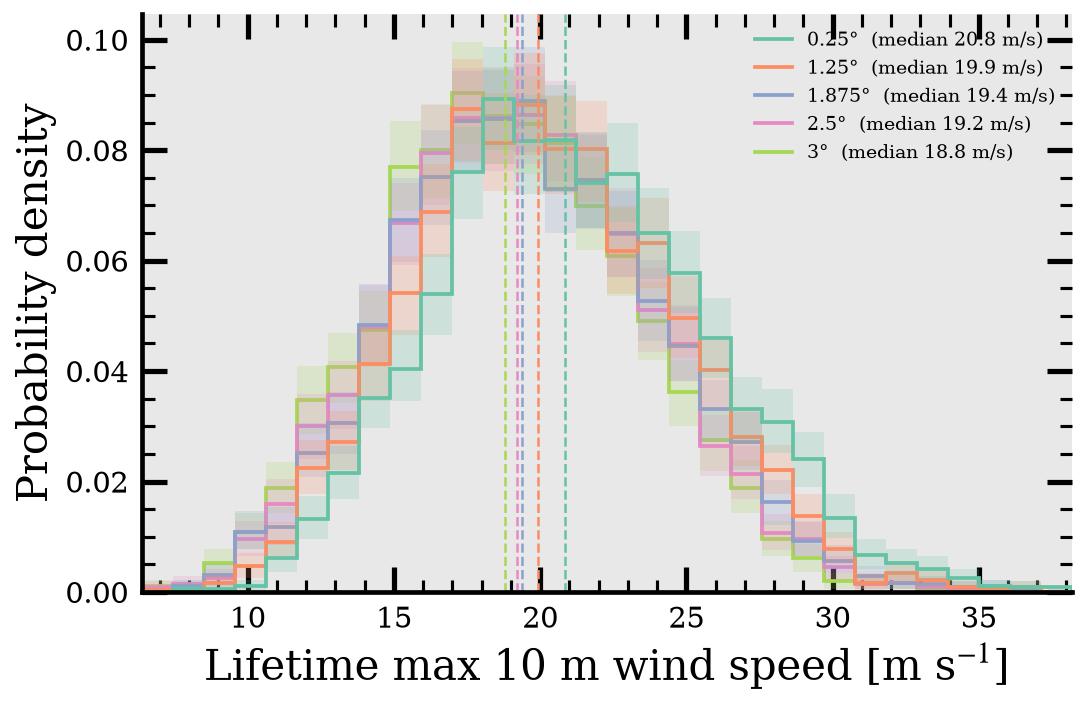

In [ ]:
fig, ax = plt.subplots(figsize=(8, 5))

plot_dist(ax, summary, "ws10_max_max", "Lifetime max 10 m wind speed [m s$^{-1}$]",
          by="sample_res", levels=SAMPLE_RES, color=SRES_COLOR,
          unit=" m/s", fmt=".1f", group_col="track_key", clip_pct=100)
ax.grid(False)

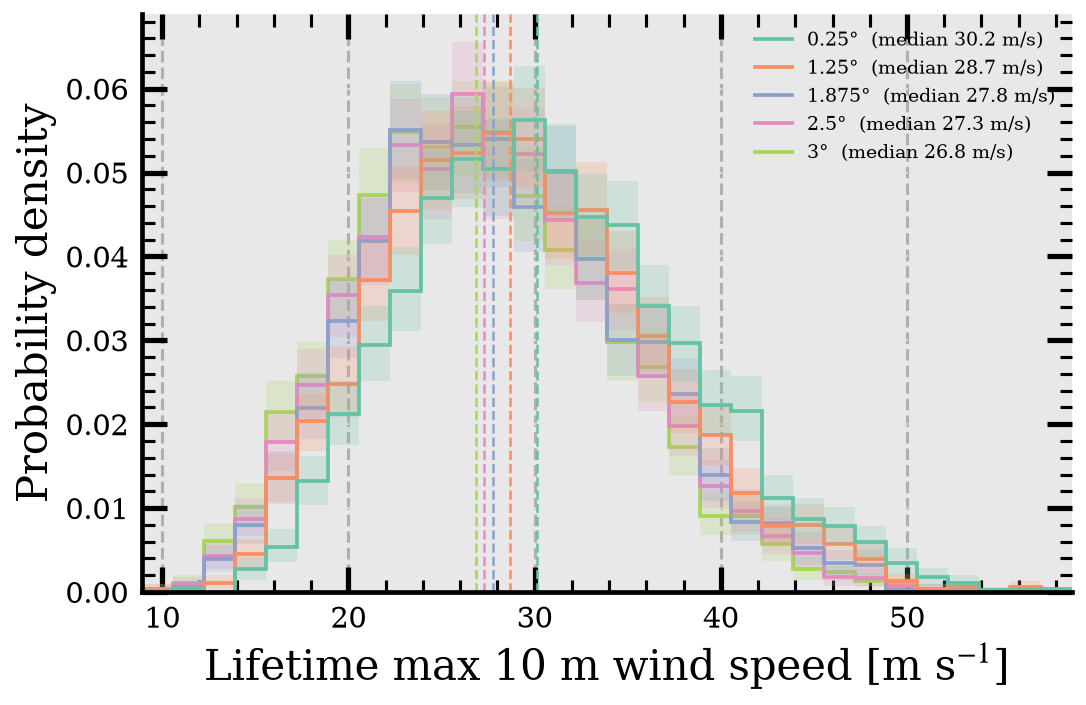

In [ ]:
fig, ax = plt.subplots(figsize=(8, 5))

plot_dist(ax, summary, "gust10_max_max", "Lifetime max 10 m wind speed [m s$^{-1}$]",
          by="sample_res", levels=SAMPLE_RES, color=SRES_COLOR,
          unit=" m/s", fmt=".1f", group_col="track_key", clip_pct=100)
ax.grid(False)

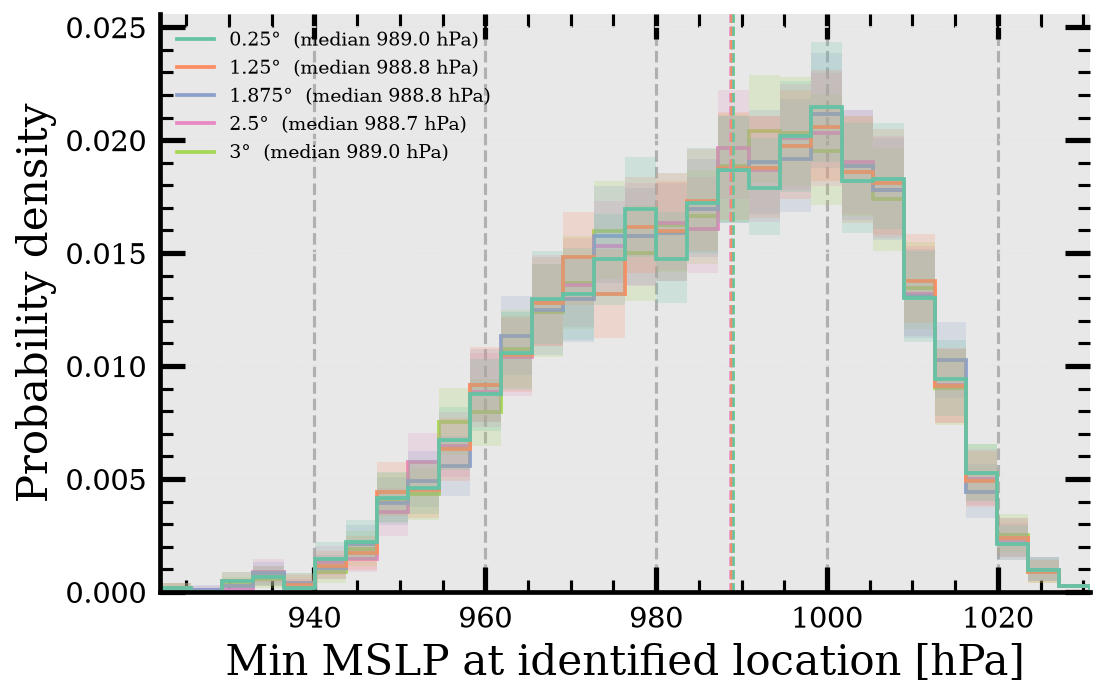

In [ ]:
fig, ax = plt.subplots(figsize=(8, 5))

plot_dist(ax, summary, 'msl_center_min', "Min MSLP at identified location [hPa]",
          by="sample_res", levels=SAMPLE_RES, color=SRES_COLOR,
          unit=" hPa", fmt=".1f", group_col="track_key", clip_pct=100)
ax.grid(False)

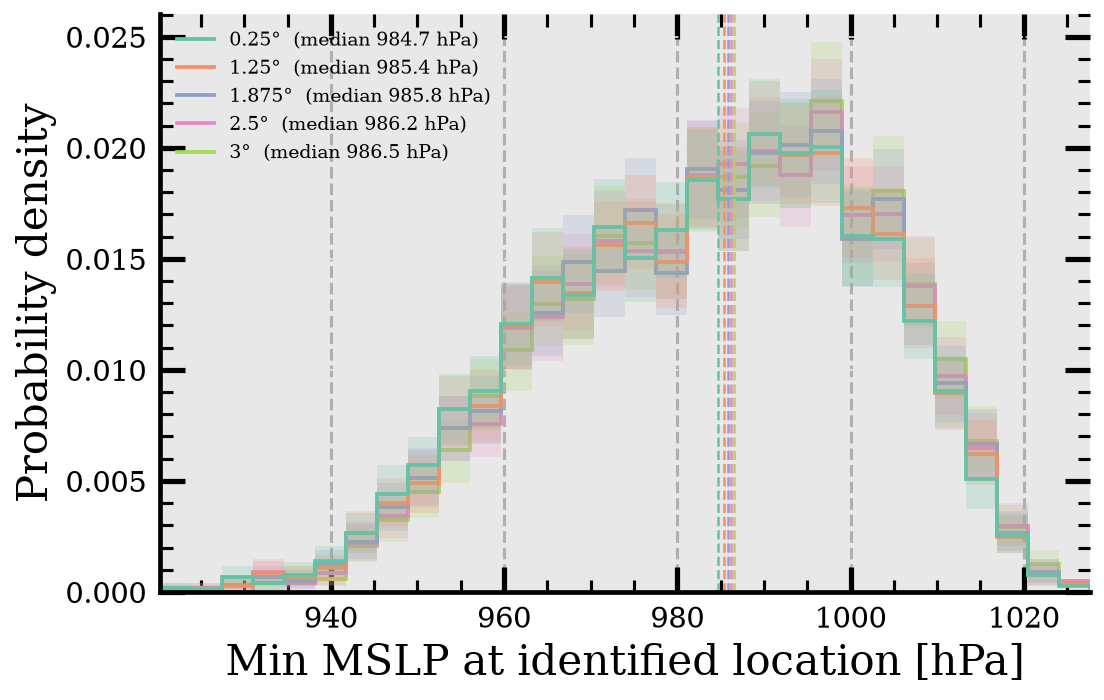

In [ ]:
fig, ax = plt.subplots(figsize=(8, 5))
plot_dist(ax, summary, 'msl_min_min', "Min MSLP at identified location [hPa]",
          by="sample_res", levels=SAMPLE_RES, color=SRES_COLOR,
          unit=" hPa", fmt=".1f", group_col="track_key", clip_pct=100)
ax.grid(False)

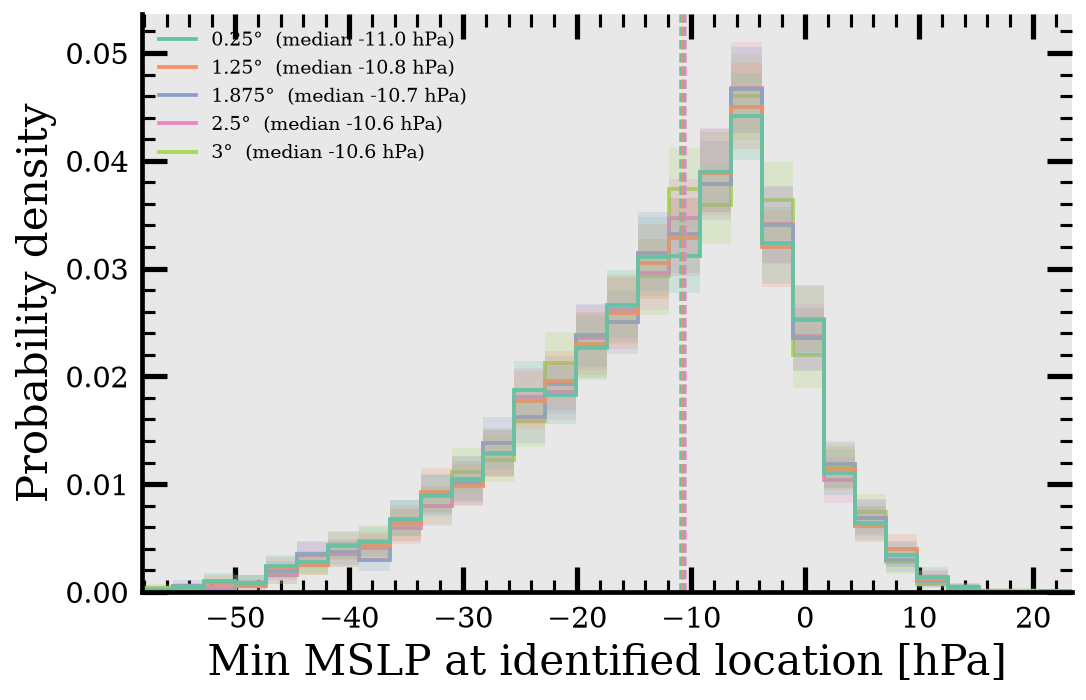

In [ ]:
fig, ax = plt.subplots(figsize=(8, 5))
plot_dist(ax, summary, 'dmsl_24h_min', "deepening MSLP in 24 h at identified location [hPa]",
          by="sample_res", levels=SAMPLE_RES, color=SRES_COLOR,
          unit=" hPa", fmt=".1f", group_col="track_key", clip_pct=100)
ax.grid(False)

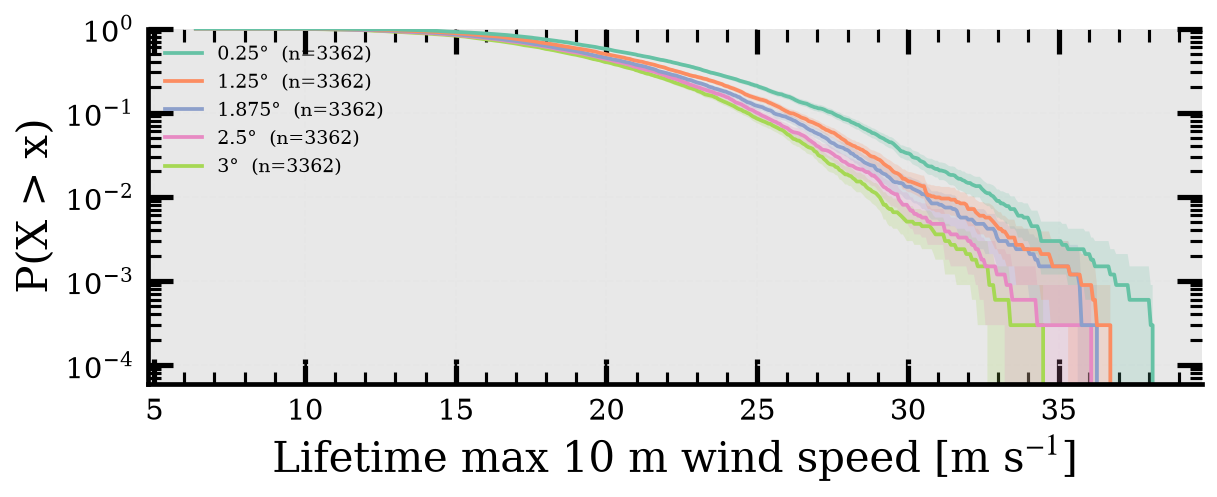

In [ ]:
def boot_exceedance(x, grid, groups=None, n_boot=1000, ci=(2.5, 97.5), seed=0):
    rng = np.random.default_rng(seed)
    x = np.asarray(x)
    def sf(s):
        s = np.sort(s)
        return 1 - np.searchsorted(s, grid, side="right") / len(s)
    if groups is None:
        samples = (x[rng.integers(0, len(x), len(x))] for _ in range(n_boot))
    else:
        groups = np.asarray(groups)
        blocks = [x[groups == g] for g in np.unique(groups)]
        samples = (np.concatenate([blocks[k] for k in rng.integers(0, len(blocks), len(blocks))])
                   for _ in range(n_boot))
    boot = np.array([sf(s) for s in samples])
    return sf(x), *np.percentile(boot, ci, axis=0)


def plot_exceedance(ax, df, var, xlabel, by="sample_res", levels=None, color=None, group_col=None):
    levels = levels or sorted(df[by].unique())
    vals = df[var].dropna()
    grid = np.linspace(vals.min(), vals.max(), 500)
    for lev in levels[::-1]:
        d = df[df[by] == lev].dropna(subset=[var])
        g = d[group_col].to_numpy() if group_col else None
        p, lo, hi = boot_exceedance(d[var].to_numpy(), grid, groups=g)
        ax.fill_between(grid, lo, hi, color=color[lev], alpha=0.2, lw=0)
        ax.plot(grid, p, color=color[lev], lw=1.8, label=f"{res_label(lev)}  (n={len(d)})")
    ax.set_yscale("log")
    ax.set_ylim(1 / len(vals), 1)  # below this the curve is just the single largest value(s)
    ax.set_xlabel(xlabel); ax.set_ylabel("P(X > x)")
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(color="0.9", lw=0.8); ax.set_axisbelow(True)
    h, l = ax.get_legend_handles_labels()
    ax.legend(h[::-1], l[::-1], frameon=False, fontsize=9)


fig, ax = plt.subplots(figsize=(8, 3.2), layout="constrained")
plot_exceedance(ax, summary, "ws10_max_max", "Lifetime max 10 m wind speed [m s$^{-1}$]",
                levels=SAMPLE_RES, color=SRES_COLOR, group_col="track_key")

loaded 2047 rows from 19981999_DJF_0p25_vo_points_sl0p25.csv
loaded 2229 rows from 19992000_DJF_0p25_vo_points_sl0p25.csv
loaded 2391 rows from 20002001_DJF_0p25_vo_points_sl0p25.csv
loaded 2308 rows from 20012002_DJF_0p25_vo_points_sl0p25.csv
loaded 2322 rows from 20022003_DJF_0p25_vo_points_sl0p25.csv
loaded 2220 rows from 20032004_DJF_0p25_vo_points_sl0p25.csv
loaded 2483 rows from 20042005_DJF_0p25_vo_points_sl0p25.csv
loaded 2640 rows from 20052006_DJF_0p25_vo_points_sl0p25.csv
loaded 2105 rows from 20062007_DJF_0p25_vo_points_sl0p25.csv
loaded 2323 rows from 20072008_DJF_0p25_vo_points_sl0p25.csv
loaded 2307 rows from 20082009_DJF_0p25_vo_points_sl0p25.csv
loaded 2260 rows from 20092010_DJF_0p25_vo_points_sl0p25.csv
loaded 2173 rows from 20102011_DJF_0p25_vo_points_sl0p25.csv
loaded 2370 rows from 20112012_DJF_0p25_vo_points_sl0p25.csv
loaded 2110 rows from 20122013_DJF_0p25_vo_points_sl0p25.csv
loaded 2073 rows from 20132014_DJF_0p25_vo_points_sl0p25.csv
loaded 2265 rows from 20

Also written to commit again